<a href="https://colab.research.google.com/github/tettehdaniel/python-labs/blob/main/Notebooks/Notebook15_OLS_SV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 15 — Ordinary Least Squares Regression

**Main Objective**

1. Simple Linear Regression
2. Multiple Linear Regression

## Setup

Please run the setup code below

In [1]:
! wget -q -nc https://raw.githubusercontent.com/taylor-arnold/fds-py/refs/heads/main/funs.py

from funs import *

In [2]:
import numpy as np
import polars as pl

from plotnine import *
from polars import col as c
theme_set(theme_minimal())

path = "https://raw.githubusercontent.com/ajcollins16/DSST289_Fall2026_AJC/refs/heads/main/"

In [3]:
dat = pl.read_csv(path + "Data/IBM_HR_Analytics.csv")

## Linear Regression

The IBM HR Analytics dataset contains information about 1,470 employees and provides a variety of measures related to their work experience, compensation, job characteristics, and workplace attitudes. The version of the dataset used in these notebooks contains 16 variables. Several are quantitative measures, including `MonthlyIncome`, `HourlyRate`, `MonthlyRate`, `TotalWorkingYears`, `YearsAtCompany`, and `YearsInCurrentRole`. Other variables describe categorical characteristics of the employee or their job, such as `Department`, `Education`, `EducationField`, and `Gender`, as well as measures of job involvement, job satisfaction, work-life balance, performance, and relationship satisfaction.

This combination of quantitative and categorical variables makes the dataset particularly useful for exploring relationships among employee characteristics. Throughout these notebooks, we will use these variables to investigate how different aspects of an employee's background and work experience can be used to predict their monthly income.


### Questions

1. Our overall goal is to determine which employee characteristics are most useful for predicting `MonthlyIncome`. To start, using the variables `TotalWorkingYears`, `YearsAtCompany`, and `YearsInCurrentRole` along with `MonthlyIncome`, calculate the mean and standard deviation of each variable so that we have a better understanding of the scales on which these measures are recorded.

In [6]:
dat.head(1)

Department,Attrition,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobSatisfaction,MonthlyIncome,MonthlyRate,PerformanceRating,RelationshipSatisfaction,TotalWorkingYears,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole
str,str,str,str,str,str,i64,str,str,i64,i64,str,str,i64,str,i64,i64
"""Sales""","""Yes""","""College""","""Life Sciences""","""Medium""","""Female""",94,"""High""","""Very High""",5993,19479,"""Excellent""","""Low""",8,"""Bad""",6,4


In [5]:
(
    dat
    .group_by(c.TotalWorkingYears, c.YearsAtCompany, c.MonthlyIncome)
    .agg(
        TWY_mean = c.TotalWorkingYears.mean(),
        TWY_std = c.TotalWorkingYears.std(),
        YAC_mean = c.YearsAtCompany.mean(),
        YAC_std = c.YearsAtCompany.std(),
        MI_mean = c.MonthlyIncome.mean(),
        MI_std = c.MonthlyIncome.std()
    )
    .fill_null(0)
)

TotalWorkingYears,YearsAtCompany,MonthlyIncome,TWY_mean,TWY_std,YAC_mean,YAC_std,MI_mean,MI_std
i64,i64,i64,f64,f64,f64,f64,f64,f64
1,1,2716,1.0,0.0,1.0,0.0,2716.0,0.0
11,8,4335,11.0,0.0,8.0,0.0,4335.0,0.0
10,10,6524,10.0,0.0,10.0,0.0,6524.0,0.0
1,1,2566,1.0,0.0,1.0,0.0,2566.0,0.0
7,4,2277,7.0,0.0,4.0,0.0,2277.0,0.0
…,…,…,…,…,…,…,…,…
4,4,3140,4.0,0.0,4.0,0.0,3140.0,0.0
17,3,9602,17.0,0.0,3.0,0.0,9602.0,0.0
16,15,4440,16.0,0.0,15.0,0.0,4440.0,0.0


2. Now let's visually explore how certain variables relate to `MonthlyIncome`. Create a scatterplot showing `MonthlyIncome` on the y-axis and `HourlyRate` on the x-axis. Make the color of each point "grey". Then add a linear best fit line (`geom_smooth(method = "lm", se = False)`) to the scatterplot and make that best fit line "red" in color.

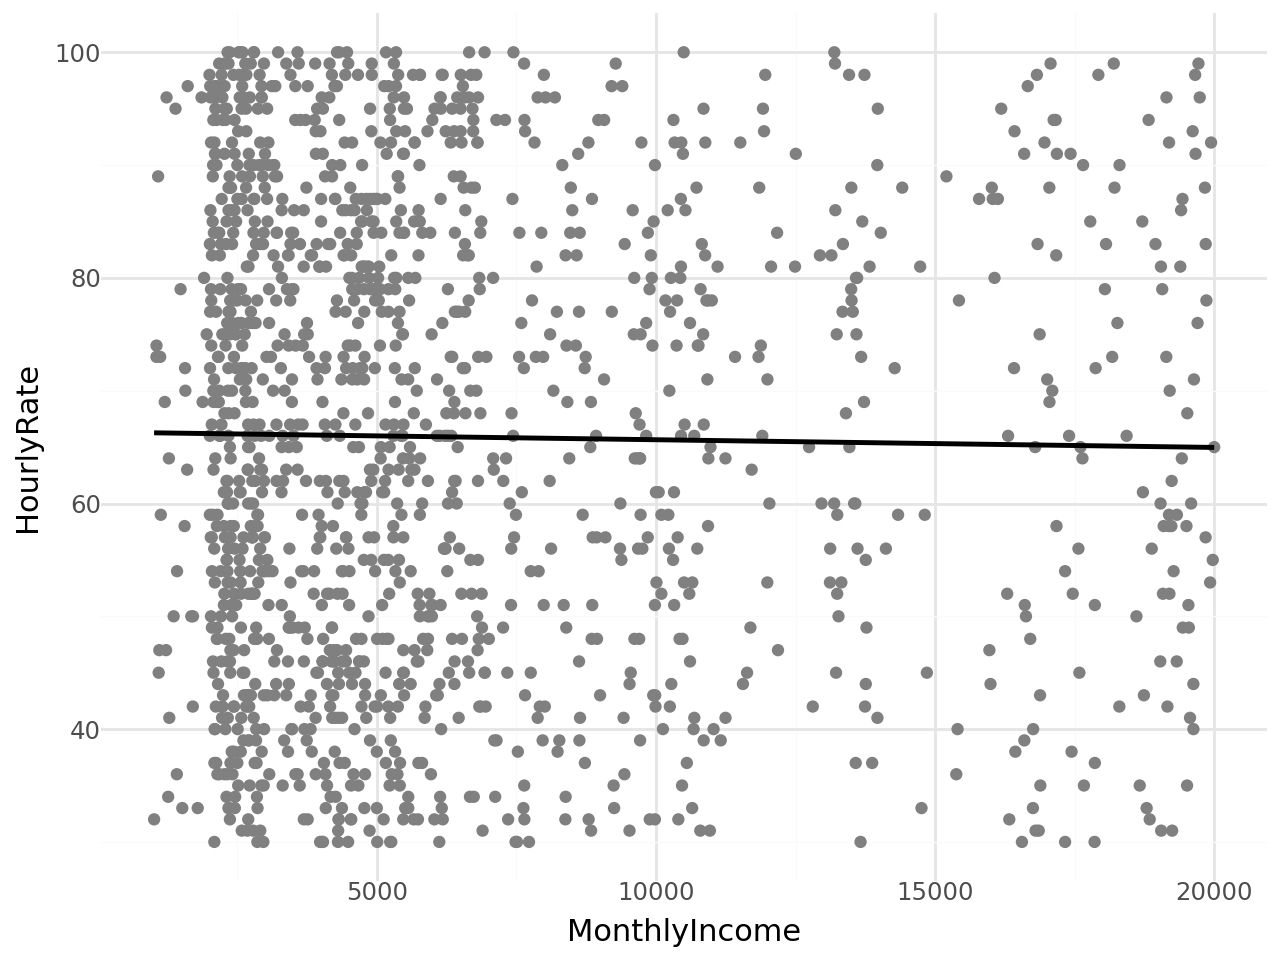

In [8]:
(
    dat
    .pipe(ggplot, aes(x = "MonthlyIncome", y = "HourlyRate"))
    + geom_point(color="grey")
    + geom_smooth(method="lm", se=False)
)

3. Now create a different scatter plot showing `MonthlyIncome` on the y-axis and `YearsAtCompany` on the x-axis, using all the same colors and best fit line from question 2.

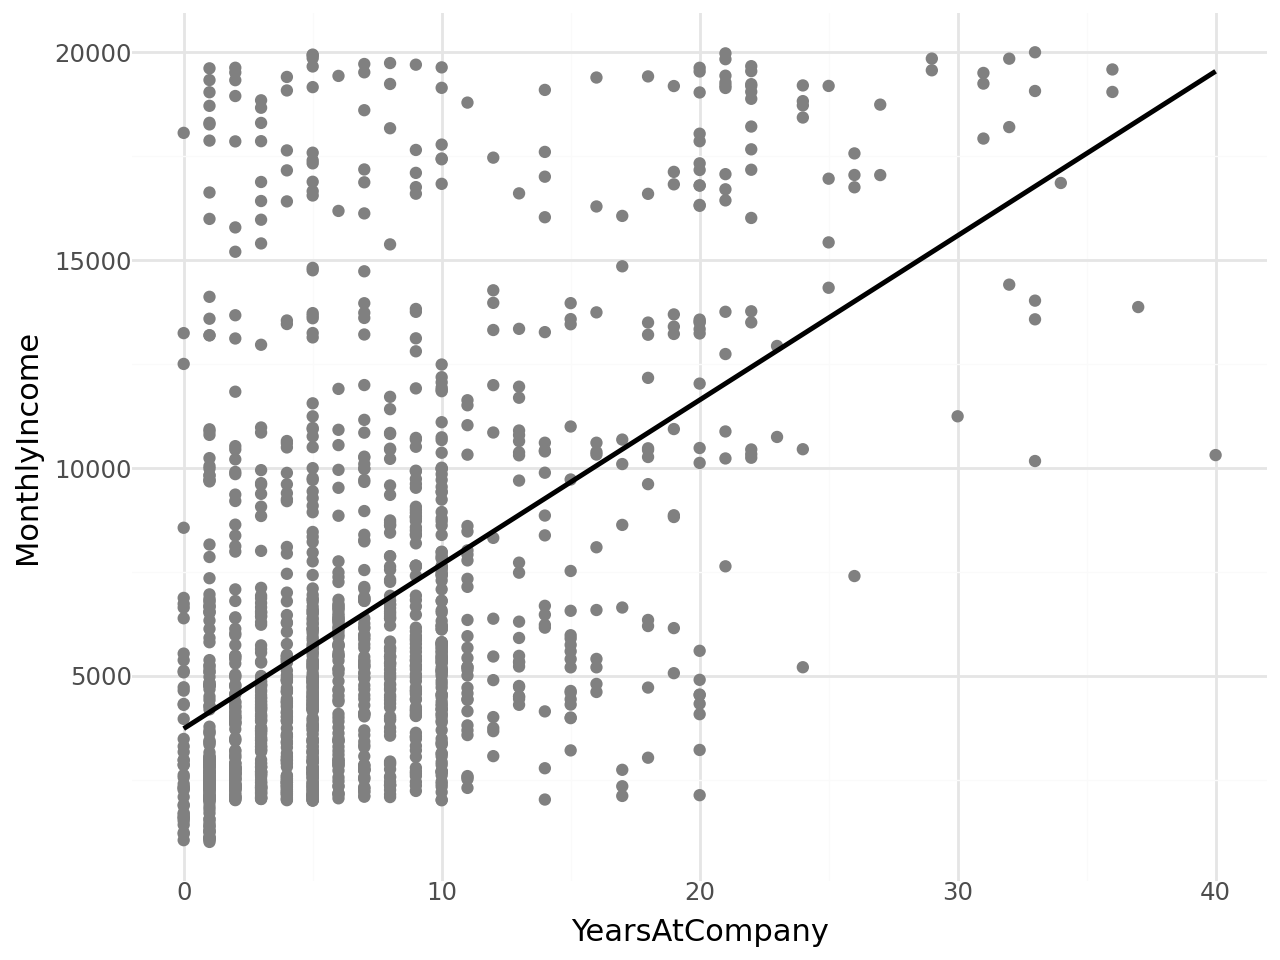

In [9]:
(
    dat
    .pipe(ggplot, aes(x = "YearsAtCompany", y = "MonthlyIncome"))
    + geom_point(color="grey")
    + geom_smooth(method="lm", se=False)
)

4. Now from the two visuals made above, which variable (i.e., `HourlyRate` or `YearsAtCompany`) appears to have the strongest relationship with `MonthlyIncome`. Explain a little on why you said what said.

**Answer (Q4):** YearsAtCompany appears to have the strongest relationship with MonthlyIncome because the best fit line shows a positive correlation.

5. We will begin our statistical modeling using `YearsAtCompany` as a **predictor** of `MonthlyIncome`. So, fit an ordinary least squares regression model predicting `MonthlyIncome` from `YearsAtCompany`.

In [11]:
(
    dat
    .pipe(DSStatsmodels.ols, "MonthlyIncome ~ YearsAtCompany")
)

,coef,std err,t,P>|t|,[0.025,0.975]
str,f64,f64,f64,f64,f64,f64
"""Intercept""",3733.2731,160.091,23.32,0.0,3419.242,4047.305
"""YearsAtCompany""",395.2046,17.201,22.976,0.0,361.464,428.945


6. Using the regression output above, identify:

- **First.** The y-intercept: **Answer:** 3733.3
- **Second.** The slope: **Answer:** 395.2
- **Third.** The regression equation: **Answer:** y = (3733.3)+x(395.2)

7. Now interpret the slope from above. In other words, according to our model, how much would we expect an employee's predicted monthly income to change for each additional year of worked at that company?

**Answer (Q7:)**

8. Continuing to use the output from question 5. Identify the p-value for our predictor variable `YearsAtCompany`. Then with that p-value determine whether `YearsAtCompany` provides statistically significant evidence for predicting `MonthlyIncome`.

- **First.** What is the p-value? **Answer:** Lower than 0.05
- **Second.** What is our conclusion on if `YearsAtCompany` predicts `MonthlyIncome`? **Answer:** The relationship between the two is statistically significant

9. Now, let's extend our model. Fit a multiple ordinary least squares regression model predicting `MonthlyIncome` from `YearsAtCompany`, `TotalWorkingYears`, and `YearsInCurrentRole`.

In [12]:
(
    dat
    .pipe(DSStatsmodels.ols, "MonthlyIncome ~ YearsAtCompany + TotalWorkingYears + YearsInCurrentRole")
)

,coef,std err,t,P>|t|,[0.025,0.975]
str,f64,f64,f64,f64,f64,f64
"""Intercept""",1226.4641,144.184,8.506,0.0,943.636,1509.292
"""YearsAtCompany""",56.7189,22.266,2.547,0.011,13.043,100.395
"""TotalWorkingYears""",449.0275,12.864,34.905,0.0,423.793,474.262
"""YearsInCurrentRole""",-43.9498,33.001,-1.332,0.183,-108.684,20.784


10. Let us first focus on the one predictor that is similar in this model from question 9 and the model ran in question 5; `YearsAtCompany`. Harpen back to the slope coefficient extracted from question five and compare it to the same slope coefficient extracted from question 9.

- **First.** What again was the slope for `YearsAtCompany` from question 5? **Answer:** 395.2
- **Second.** What now is the slope for `YearsAtCompany` from question 9? **Answer:** 56.7
- **Third.** Compare the two slopes. Are they the same (roughly), different, etc? **Answer:** They are very different
- **Fourth.** Why do you think the model slope has changed the way it did? **Answer:** Maybe because the model is working with more than one variables.

11. Now, narrowing in on the model from question 9, which variables provide evidence of making a unique contribution toward predicting MonthlyIncome after accounting for the other predictors?

**Answer (Q11):** TotalWorkingYears

12. Create a scatter plot identical to that of question 2 and 3, but now with the best predictor extracted from question 11 on the x-axis and `MonthlyIncome` on the y-axis.

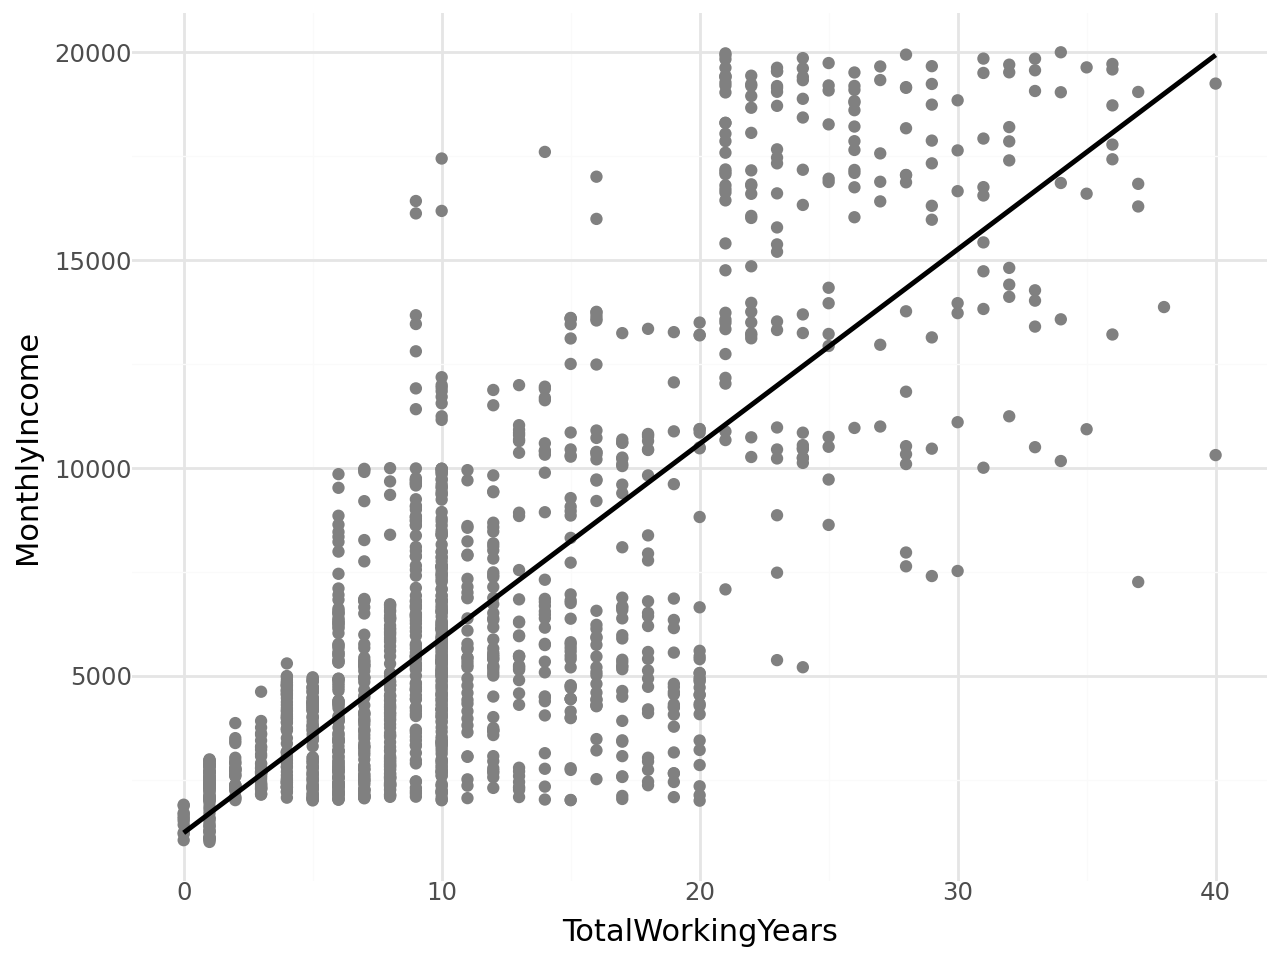

In [13]:
(
    dat
    .pipe(ggplot, aes(x = "TotalWorkingYears", y = "MonthlyIncome"))
    + geom_point(color="grey")
    + geom_smooth(method="lm", se=False)
)